# Reflection Pattern: Practice Exercise - SOLUTION

Build a **Report Writing Agent** that uses the reflection pattern to iteratively improve content quality. This exercise reinforces using separate generation and reflection models, building reflection loops with controlled iterations, and implementing multi-step workflows in LangGraph.

**What you'll implement:**
- An outline generation node with reflection (max 2 iterations)
- A research node using Tavily web search
- A report writing node with reflection (max 2 iterations)

**Estimated time:** 20 minutes

## Setup

Run this cell to import all required libraries and configure the environment.

In [2]:
# Setup - run this cell first

from dotenv import load_dotenv
import os
from typing import TypedDict, List, Annotated
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_community.tools.tavily_search import TavilySearchResults
import operator

# Load environment variables
load_dotenv()
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found in environment"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY not found in environment"

# Initialize models - using different models for generation vs reflection
generator_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.7)
reflector_llm = ChatOpenAI(model="gpt-4o", temperature=0)

# Initialize Tavily search tool
tavily_tool = TavilySearchResults(max_results=3)

# Constants
MAX_REFLECTION_ITERATIONS = 2

print("Setup complete!")
print(f"Generator model: gpt-4o-mini")
print(f"Reflector model: gpt-4o")
print(f"Max reflection iterations: {MAX_REFLECTION_ITERATIONS}")

Setup complete!
Generator model: gpt-4o-mini
Reflector model: gpt-4o
Max reflection iterations: 2


/var/folders/_1/tfp0k5355jxb501q_ckbc6m80000gn/T/ipykernel_29211/1150641834.py:22: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily_tool = TavilySearchResults(max_results=3)


## Context

You are building a Report Writing Agent that produces high-quality research reports. The workflow uses the **reflection pattern** where a "reflector" model critiques the output of a "generator" model, enabling iterative improvement.

**Workflow:**
1. **Generate Outline** - Create a structured outline for the report topic
   - Reflection loop: Critique and improve the outline (max 2 iterations)
2. **Research** - Use Tavily to gather information for each outline section
3. **Write Report** - Write the full report based on outline and research
   - Reflection loop: Critique and improve the report (max 2 iterations)

**Reflection Pattern:**
- Generator creates content
- Reflector critiques and suggests improvements
- Generator incorporates feedback
- Repeat until max iterations or quality threshold

**Input:** A report topic (e.g., "The impact of AI on healthcare")

**Output:** A well-researched, refined report with:
- Clear structure from the outline
- Facts backed by web research
- Quality improved through reflection

---

## Part 1: Define the State - SOLUTION

Define the state schema for the Report Writing Agent.

In [3]:
# SOLUTION: Define all state fields for the workflow

class ReportState(TypedDict):
    """State schema for the Report Writing Agent."""
    
    # The report topic from the user
    topic: str
    
    # Current outline (updated through reflection)
    outline: str
    
    # Reflection feedback on the outline
    outline_feedback: str
    
    # Number of outline reflection iterations completed
    outline_iterations: int
    
    # Research results from Tavily
    research_results: str
    
    # Current report draft (updated through reflection)
    report: str
    
    # Reflection feedback on the report
    report_feedback: str
    
    # Number of report reflection iterations completed
    report_iterations: int
    
    # Current phase: 'outline', 'research', 'writing', 'complete'
    phase: str


print("State schema defined!")

State schema defined!


---

## Part 2: Implement the Outline Generation Node - SOLUTION

Create a node that generates or improves an outline based on the topic. If there's feedback from the reflector, incorporate it to improve the outline.

In [4]:
def generate_outline(state: ReportState) -> dict:
    """
    Generates or improves a report outline based on the topic.
    
    If outline_feedback exists, incorporates it to improve the existing outline.
    Otherwise, generates a fresh outline from the topic.
    
    Args:
        state: Current workflow state containing topic, outline, and feedback
    
    Returns:
        dict with updated 'outline' and 'phase' set to 'outline'
    """
    topic = state["topic"]
    current_outline = state.get("outline", "")
    feedback = state.get("outline_feedback", "")
    iterations = state.get("outline_iterations", 0)
    
    print(f"\nGenerating outline (iteration {iterations + 1})...")
    
    # SOLUTION: Create appropriate system prompt based on whether we have feedback
    if feedback:
        system_prompt = """You are an expert report writer. Improve the given outline based on the feedback provided.
Maintain the overall structure but address all the feedback points.
Return only the improved outline, no explanations."""
        
        user_content = f"""Topic: {topic}

Current Outline:
{current_outline}

Feedback to address:
{feedback}

Please improve the outline based on this feedback."""
    else:
        system_prompt = """You are an expert report writer. Create a detailed outline for a report on the given topic.
Include:
- A clear introduction section
- 3-4 main sections with subsections
- A conclusion section
Return only the outline in a clear hierarchical format."""
        
        user_content = f"Create a detailed outline for a report on: {topic}"
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_content)
    ]
    
    response = generator_llm.invoke(messages)
    outline = response.content.strip()
    
    print(f"Outline generated ({len(outline)} characters)")
    
    return {
        "outline": outline,
        "phase": "outline"
    }


print("generate_outline node created!")

generate_outline node created!


---

## Part 3: Implement the Outline Reflection Node - SOLUTION

Create a node that critiques the outline and provides actionable feedback for improvement.

In [5]:
def reflect_on_outline(state: ReportState) -> dict:
    """
    Critiques the current outline and provides feedback for improvement.
    
    Uses the reflector model (gpt-4o) to analyze the outline and suggest
    specific improvements to structure, coverage, and organization.
    
    Args:
        state: Current workflow state containing the outline
    
    Returns:
        dict with 'outline_feedback' and incremented 'outline_iterations'
    """
    outline = state["outline"]
    topic = state["topic"]
    iterations = state.get("outline_iterations", 0)
    
    print(f"\nReflecting on outline (iteration {iterations + 1})...")
    
    # SOLUTION: Create reflection prompt
    system_prompt = """You are an expert editor reviewing a report outline. Analyze the outline and provide specific, actionable feedback.

Focus on:
1. Structure - Is the organization logical and clear?
2. Coverage - Does it fully address the topic? Any missing aspects?
3. Flow - Do sections connect logically?
4. Balance - Are sections appropriately weighted?

Provide 3-5 specific improvement suggestions. Be constructive and precise."""
    
    user_content = f"""Topic: {topic}

Outline to review:
{outline}

Please provide specific feedback for improving this outline."""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_content)
    ]
    
    response = reflector_llm.invoke(messages)
    feedback = response.content.strip()
    
    print(f"Feedback generated ({len(feedback)} characters)")
    
    return {
        "outline_feedback": feedback,
        "outline_iterations": iterations + 1
    }


print("reflect_on_outline node created!")

reflect_on_outline node created!


---

## Part 4: Implement the Research Node (Provided)

This node uses Tavily to gather research information based on the outline sections.

In [6]:
def conduct_research(state: ReportState) -> dict:
    """
    Uses Tavily to research information for the report based on the outline.
    Extracts key topics from the outline and searches for relevant information.
    """
    topic = state["topic"]
    outline = state["outline"]
    
    print("\nConducting research...")
    
    # Generate search queries based on topic and outline
    query_prompt = f"""Based on this report topic and outline, generate 3 specific search queries 
to gather relevant information. Return only the queries, one per line.

Topic: {topic}

Outline:
{outline}"""
    
    query_response = generator_llm.invoke([HumanMessage(content=query_prompt)])
    queries = query_response.content.strip().split("\n")[:3]
    
    # Search for each query
    all_results = []
    for query in queries:
        query = query.strip()
        if query:
            print(f"  Searching: {query[:50]}...")
            try:
                results = tavily_tool.invoke({"query": query})
                for result in results:
                    all_results.append(f"Source: {result.get('url', 'N/A')}\n{result.get('content', '')}")
            except Exception as e:
                print(f"  Search failed: {e}")
    
    research_text = "\n\n---\n\n".join(all_results) if all_results else "No research results found."
    
    print(f"  Found {len(all_results)} research results")
    
    return {
        "research_results": research_text,
        "phase": "research"
    }


print("conduct_research node created!")

conduct_research node created!


---

## Part 5: Report Writing Node (Provided)

This node writes or improves the report based on the outline and research.

In [7]:
def write_report(state: ReportState) -> dict:
    """
    Writes or improves the report based on outline and research.
    
    If report_feedback exists, incorporates it to improve the existing report.
    Otherwise, generates a fresh report from the outline and research.
    """
    topic = state["topic"]
    outline = state["outline"]
    research = state["research_results"]
    current_report = state.get("report", "")
    feedback = state.get("report_feedback", "")
    iterations = state.get("report_iterations", 0)
    
    print(f"\nWriting report (iteration {iterations + 1})...")
    
    # Create appropriate system prompt based on whether we have feedback
    if feedback:
        system_prompt = """You are an expert report writer. Improve the given report based on the feedback provided.
Maintain the overall structure but address all the feedback points.
Keep the report professional, well-organized, and factually accurate.
Return only the improved report."""
        
        user_content = f"""Topic: {topic}

Current Report:
{current_report}

Feedback to address:
{feedback}

Please improve the report based on this feedback."""
    else:
        system_prompt = """You are an expert report writer. Write a comprehensive report following the given outline.
Use the research results to support your points with facts and data.
Make the report professional, well-organized, and engaging.
Include an introduction, body sections following the outline, and a conclusion."""
        
        user_content = f"""Topic: {topic}

Outline to follow:
{outline}

Research results to incorporate:
{research[:3000]}...

Please write a comprehensive report based on this outline and research."""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_content)
    ]
    
    response = generator_llm.invoke(messages)
    report = response.content.strip()
    
    print(f"Report written ({len(report)} characters)")
    
    return {
        "report": report,
        "phase": "writing"
    }


print("write_report node created!")

write_report node created!


---

## Part 6: Implement the Report Reflection Node - SOLUTION

Create a node that critiques the report and provides actionable feedback.

In [8]:
def reflect_on_report(state: ReportState) -> dict:
    """
    Critiques the current report and provides feedback for improvement.
    
    Uses the reflector model (gpt-4o) to analyze the report and suggest
    specific improvements to clarity, accuracy, and completeness.
    
    Args:
        state: Current workflow state containing the report
    
    Returns:
        dict with 'report_feedback' and incremented 'report_iterations'
    """
    report = state["report"]
    topic = state["topic"]
    outline = state["outline"]
    iterations = state.get("report_iterations", 0)
    
    print(f"\nReflecting on report (iteration {iterations + 1})...")
    
    # SOLUTION: Create reflection prompt
    system_prompt = """You are an expert editor reviewing a report. Analyze the report and provide specific, actionable feedback.

Focus on:
1. Clarity - Is the writing clear and easy to understand?
2. Accuracy - Are claims supported by evidence?
3. Completeness - Does it fully cover the outline topics?
4. Engagement - Is it interesting and well-written?
5. Structure - Does it flow logically?

Provide 3-5 specific improvement suggestions. Be constructive and precise."""
    
    user_content = f"""Topic: {topic}

Original Outline:
{outline}

Report to review:
{report[:4000]}...

Please provide specific feedback for improving this report."""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_content)
    ]
    
    response = reflector_llm.invoke(messages)
    feedback = response.content.strip()
    
    print(f"Feedback generated ({len(feedback)} characters)")
    
    return {
        "report_feedback": feedback,
        "report_iterations": iterations + 1
    }


print("reflect_on_report node created!")

reflect_on_report node created!


---

## Part 6a: Output Generation Node (Provided)

This node generates the final formatted output summary after all reflections are complete.

In [9]:
def generate_output(state: ReportState) -> dict:
    """
    Generates a final formatted output with summary statistics about the workflow.
    This node runs after all reflections are complete.
    """
    topic = state["topic"]
    outline = state["outline"]
    report = state["report"]
    outline_iterations = state.get("outline_iterations", 0)
    report_iterations = state.get("report_iterations", 0)
    
    print("\n" + "=" * 60)
    print("GENERATING FINAL OUTPUT")
    print("=" * 60)
    
    # Generate a brief executive summary
    summary_prompt = f"""Based on this report, write a 2-3 sentence executive summary that captures the key insights.

Report:
{report[:2000]}...

Return only the executive summary, nothing else."""
    
    response = generator_llm.invoke([HumanMessage(content=summary_prompt)])
    executive_summary = response.content.strip()
    
    # Create formatted output
    output = f"""
{'='*60}
REPORT GENERATION COMPLETE
{'='*60}

Topic: {topic}

Executive Summary:
{executive_summary}

Statistics:
- Outline iterations: {outline_iterations}
- Report iterations: {report_iterations}
- Outline length: {len(outline)} characters
- Report length: {len(report)} characters

{'='*60}
"""
    
    print(output)
    
    return {
        "phase": "complete"
    }


print("generate_output node created!")

generate_output node created!


---

## Part 7: Define Routing Logic - SOLUTION

Implement the conditional routing functions that control the reflection loops.

In [10]:
def route_after_outline_reflection(state: ReportState) -> str:
    """
    Determines whether to continue refining the outline or move to research.
    
    Returns:
        'generate_outline' if more iterations needed (< MAX_REFLECTION_ITERATIONS)
        'conduct_research' if max iterations reached
    """
    # SOLUTION: Check iteration count against max
    iterations = state.get("outline_iterations", 0)
    
    if iterations < MAX_REFLECTION_ITERATIONS:
        print(f"  -> Continuing outline refinement (iteration {iterations}/{MAX_REFLECTION_ITERATIONS})")
        return "generate_outline"
    else:
        print(f"  -> Max outline iterations reached, moving to research")
        return "conduct_research"


def route_after_report_reflection(state: ReportState) -> str:
    """
    Determines whether to continue refining the report or move to output generation.
    
    Returns:
        'write_report' if more iterations needed (< MAX_REFLECTION_ITERATIONS)
        'generate_output' if max iterations reached
    """
    # SOLUTION: Check iteration count against max
    iterations = state.get("report_iterations", 0)
    
    if iterations < MAX_REFLECTION_ITERATIONS:
        print(f"  -> Continuing report refinement (iteration {iterations}/{MAX_REFLECTION_ITERATIONS})")
        return "write_report"
    else:
        print(f"  -> Max report iterations reached, generating output")
        return "generate_output"


print("Routing functions defined!")

Routing functions defined!


---

## Part 8: Build and Compile the Graph

Wire everything together into a complete workflow with reflection loops.

In [11]:
# Build the graph
workflow = StateGraph(ReportState)

# Add nodes
workflow.add_node("generate_outline", generate_outline)
workflow.add_node("reflect_outline", reflect_on_outline)
workflow.add_node("conduct_research", conduct_research)
workflow.add_node("write_report", write_report)
workflow.add_node("reflect_report", reflect_on_report)
workflow.add_node("generate_output", generate_output)

# Add edges for outline phase
workflow.add_edge(START, "generate_outline")
workflow.add_edge("generate_outline", "reflect_outline")
workflow.add_conditional_edges(
    "reflect_outline",
    route_after_outline_reflection,
    {
        "generate_outline": "generate_outline",
        "conduct_research": "conduct_research"
    }
)

# Add edges for research -> writing phase
workflow.add_edge("conduct_research", "write_report")
workflow.add_edge("write_report", "reflect_report")
workflow.add_conditional_edges(
    "reflect_report",
    route_after_report_reflection,
    {
        "write_report": "write_report",
        "generate_output": "generate_output"
    }
)

# Add final edge from output to END
workflow.add_edge("generate_output", END)

# Compile the graph
app = workflow.compile()

print("Graph compiled!")
print("\nWorkflow structure:")
print("  START -> generate_outline <-> reflect_outline (max 2 iterations)")
print("    -> conduct_research")
print("    -> write_report <-> reflect_report (max 2 iterations)")
print("    -> generate_output -> END")

Graph compiled!

Workflow structure:
  START -> generate_outline <-> reflect_outline (max 2 iterations)
    -> conduct_research
    -> write_report <-> reflect_report (max 2 iterations)
    -> generate_output -> END


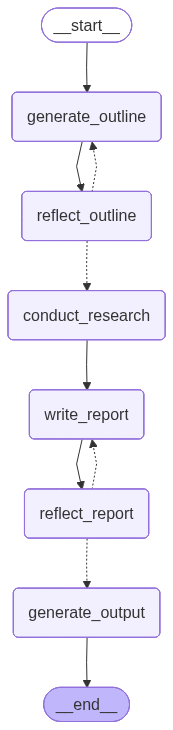

In [12]:
# Visualize the graph (optional)
try:
    from IPython.display import Image, display
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Visualization not available: {e}")

---

## Run Your Implementation

Test the reflection workflow with a sample report topic.

In [13]:
# Run the report writing workflow
print("Starting Report Writing Agent")
print("=" * 60)

initial_state = {
    "topic": "The impact of renewable energy on global economics",
    "outline": "",
    "outline_feedback": "",
    "outline_iterations": 0,
    "research_results": "",
    "report": "",
    "report_feedback": "",
    "report_iterations": 0,
    "phase": "outline"
}

# Run the workflow
final_state = app.invoke(initial_state)

print("\n" + "=" * 60)
print("WORKFLOW COMPLETE")
print("=" * 60)

Starting Report Writing Agent

Generating outline (iteration 1)...
Outline generated (2330 characters)

Reflecting on outline (iteration 1)...
Feedback generated (2167 characters)
  -> Continuing outline refinement (iteration 1/2)

Generating outline (iteration 2)...
Outline generated (2849 characters)

Reflecting on outline (iteration 2)...
Feedback generated (2939 characters)
  -> Max outline iterations reached, moving to research

Conducting research...
  Searching: 1. "economic impact of renewable energy on global ...
  Searching: 2. "job creation in renewable energy sectors vs tr...
  Searching: 3. "challenges of integrating renewable energy int...
  Found 9 research results

Writing report (iteration 1)...
Report written (10845 characters)

Reflecting on report (iteration 1)...
Feedback generated (2906 characters)
  -> Continuing report refinement (iteration 1/2)

Writing report (iteration 2)...
Report written (14061 characters)

Reflecting on report (iteration 2)...
Feedback gen

In [14]:
# Display the final outline
print("FINAL OUTLINE")
print("=" * 60)
print(final_state["outline"])

FINAL OUTLINE
# Outline: The Impact of Renewable Energy on Global Economics

## I. Introduction
   A. Definition of Renewable Energy
   B. Overview of Global Energy Consumption Trends
   C. Importance of Studying the Economic Impact of Renewable Energy
   D. Objectives of the Report
   E. Transition to Current State of Renewable Energy

## II. The Current State of Renewable Energy
   A. Types of Renewable Energy Sources
      1. Solar Energy
      2. Wind Energy
      3. Hydropower
      4. Biomass and Geothermal Energy
   B. Global Adoption Rates
      1. Key Statistics and Trends
      2. Regional Variations
   C. Technological Advancements
      1. Innovations in Renewable Technologies
      2. Cost Reductions and Efficiency Improvements
   D. Transition to Economic Benefits of Renewable Energy

## III. Economic Benefits of Renewable Energy
   A. Job Creation
      1. Employment in Renewable Energy Sectors
      2. Comparison with Traditional Energy Jobs
   B. Investment Opportuniti

In [15]:
# Display the final report
print("FINAL REPORT")
print("=" * 60)
print(final_state["report"])

FINAL REPORT
# The Impact of Renewable Energy on Global Economics

## I. Introduction

### A. Definition of Renewable Energy
Renewable energy refers to energy derived from natural processes that are replenished at a faster rate than they are consumed. This includes a variety of sources such as solar, wind, hydropower, biomass, and geothermal energy. These energy forms are increasingly recognized for their potential to reduce greenhouse gas emissions and contribute to sustainability.

### B. Overview of Global Energy Consumption Trends
The global energy landscape is undergoing a significant transformation, with renewable energy sources gaining traction. According to the International Energy Agency (IEA), renewables accounted for nearly 29% of global electricity generation in 2022, a figure projected to rise as nations strive to meet climate targets. Projections suggest that by 2030, renewable sources could contribute over 50% of global electricity generation, driven by technological adv